<a href="https://colab.research.google.com/github/kodihasini/2520090209_DeepLearning/blob/main/DeepLearning_Skill8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Runtime settings.")


PyTorch Version: 2.14.1+cpu
CUDA Available: False
Please enable GPU in Runtime settings.


In [3]:

import torch
import torch.nn as nn
import numpy as np
import time
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Running on:", device)


Running on: cpu


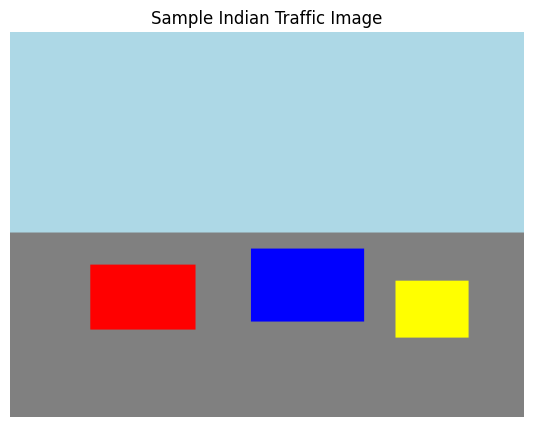

In [4]:

from PIL import Image, ImageDraw

# Create a sample traffic scene
img = Image.new("RGB", (640, 480), color="lightblue")
draw = ImageDraw.Draw(img)

# Road
draw.rectangle([0, 250, 640, 480], fill="gray")

# Vehicles
draw.rectangle([100, 290, 230, 370], fill="red")
draw.rectangle([300, 270, 440, 360], fill="blue")
draw.rectangle([480, 310, 570, 380], fill="yellow")

# Display image
plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title("Sample Indian Traffic Image")
plt.axis("off")
plt.show()


In [5]:

def preprocess(image):
    image = image.resize((224, 224))
    image_array = np.array(image, dtype=np.float32) / 255.0

    tensor = torch.from_numpy(image_array)
    tensor = tensor.permute(2, 0, 1)
    tensor = tensor.unsqueeze(0)

    return tensor

start = time.perf_counter()

input_tensor = preprocess(img)

cpu_preprocessing_time = (
    time.perf_counter() - start
) * 1000

print("Input Shape:", input_tensor.shape)
print("CPU Preprocessing Time:", cpu_preprocessing_time, "ms")


Input Shape: torch.Size([1, 3, 224, 224])
CPU Preprocessing Time: 31.948565999982748 ms


In [6]:

start = time.perf_counter()

gpu_input = input_tensor.to(device)

if device.type == "cuda":
    torch.cuda.synchronize()

h2d_time = (time.perf_counter() - start) * 1000

print("Tensor Device:", gpu_input.device)
print("Host-to-Device Transfer:", h2d_time, "ms")


Tensor Device: cpu
Host-to-Device Transfer: 6.138453000005484 ms


In [7]:

class TrafficCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 56 * 56, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        return self.network(x)


model = TrafficCNN().to(device)
model.eval()

print("CNN Model Successfully Loaded!")
print("Model Device:", next(model.parameters()).device)


CNN Model Successfully Loaded!
Model Device: cpu


In [8]:

# Warm-up
with torch.inference_mode():
    for _ in range(5):
        _ = model(gpu_input)

if device.type == "cuda":
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.inference_mode():
    output = model(gpu_input)

if device.type == "cuda":
    torch.cuda.synchronize()

gpu_execution_time = (
    time.perf_counter() - start
) * 1000

print("Output Shape:", output.shape)
print("GPU Execution Time:", gpu_execution_time, "ms")


Output Shape: torch.Size([1, 5])
GPU Execution Time: 23.410962000014024 ms


In [9]:

start = time.perf_counter()

cpu_output = output.cpu()

d2h_time = (time.perf_counter() - start) * 1000

print("Output Device:", cpu_output.device)
print("Device-to-Host Transfer:", d2h_time, "ms")


Output Device: cpu
Device-to-Host Transfer: 0.8187319999706233 ms


In [10]:

start = time.perf_counter()

predicted_class = torch.argmax(cpu_output, dim=1).item()
confidence = torch.softmax(cpu_output, dim=1).max().item()

cpu_postprocessing_time = (
    time.perf_counter() - start
) * 1000

print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 4))
print("CPU Postprocessing Time:",
      cpu_postprocessing_time, "ms")


Predicted Class: 3
Confidence: 0.2153
CPU Postprocessing Time: 19.550584999990406 ms


In [11]:

import time

start = time.perf_counter()

# Simulate a small request waiting time
time.sleep(0.05)

serving_queue_time = (
    time.perf_counter() - start
) * 1000

print("Serving Queue Time:",
      serving_queue_time, "ms")


Serving Queue Time: 50.36312900000439 ms


In [12]:

results = {
    "CPU Preprocessing": cpu_preprocessing_time,
    "Host-to-Device Transfer": h2d_time,
    "GPU Kernel Execution": gpu_execution_time,
    "Device-to-Host Transfer": d2h_time,
    "CPU Postprocessing": cpu_postprocessing_time,
    "Serving Queue": serving_queue_time
}

df = pd.DataFrame(
    list(results.items()),
    columns=["Inference Stage", "Time (ms)"]
)

print(df.to_string(index=False))

total_time = sum(results.values())

print("\nTotal Inference Pipeline Time:",
      round(total_time, 3), "ms")


        Inference Stage  Time (ms)
      CPU Preprocessing  31.948566
Host-to-Device Transfer   6.138453
   GPU Kernel Execution  23.410962
Device-to-Host Transfer   0.818732
     CPU Postprocessing  19.550585
          Serving Queue  50.363129

Total Inference Pipeline Time: 132.23 ms


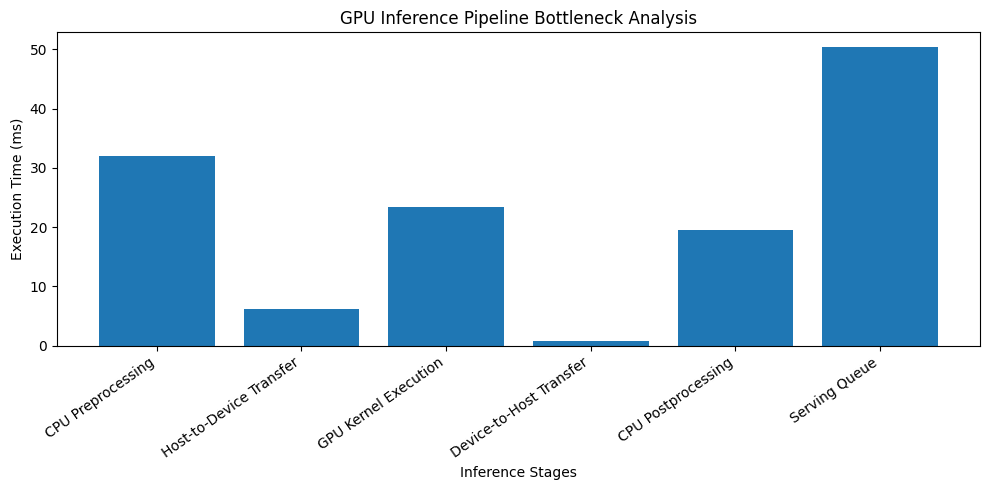

In [13]:

plt.figure(figsize=(10, 5))

plt.bar(
    results.keys(),
    results.values()
)

plt.title("GPU Inference Pipeline Bottleneck Analysis")
plt.xlabel("Inference Stages")
plt.ylabel("Execution Time (ms)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


In [14]:

bottleneck = max(results, key=results.get)

print("SYSTEM BOTTLENECK:", bottleneck)
print("Time Taken:", round(results[bottleneck], 3), "ms")

if bottleneck == "CPU Preprocessing":
    print("Optimization: Use faster image preprocessing.")
elif bottleneck == "Host-to-Device Transfer":
    print("Optimization: Use pinned memory and non-blocking transfers.")
elif bottleneck == "GPU Kernel Execution":
    print("Optimization: Use optimized models, FP16 or TensorRT.")
elif bottleneck == "Device-to-Host Transfer":
    print("Optimization: Reduce unnecessary GPU-to-CPU transfers.")
elif bottleneck == "CPU Postprocessing":
    print("Optimization: Vectorize and simplify postprocessing.")
elif bottleneck == "Serving Queue":
    print("Optimization: Improve batching and serving capacity.")


SYSTEM BOTTLENECK: Serving Queue
Time Taken: 50.363 ms
Optimization: Improve batching and serving capacity.


In [15]:

print("========== SKILL 8 REPORT ==========")

print("Project: GPU Inference Execution Path")
print("Device:", device)

for stage, duration in results.items():
    print(f"{stage}: {duration:.3f} ms")

print("------------------------------------")
print("Total Time:", round(total_time, 3), "ms")
print("Main Bottleneck:", bottleneck)

print("------------------------------------")
print("STATUS: INFERENCE PIPELINE COMPLETED")


========== SKILL 8 REPORT ==========
Project: GPU Inference Execution Path
Device: cpu
CPU Preprocessing: 31.949 ms
Host-to-Device Transfer: 6.138 ms
GPU Kernel Execution: 23.411 ms
Device-to-Host Transfer: 0.819 ms
CPU Postprocessing: 19.551 ms
Serving Queue: 50.363 ms
------------------------------------
Total Time: 132.23 ms
Main Bottleneck: Serving Queue
------------------------------------
STATUS: INFERENCE PIPELINE COMPLETED
